# GrC Image Matting on CBIS-DDSM - Layer 5, Evaluation and Ablation 

## State restoration

In [ ]:
# Imports and config
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time, gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
import joblib
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v2"
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED)

LAP_WINDOW, LAP_EPSILON = 3, 1e-7
MU_GRID = [0.1, 1.0, 10.0]            # weight of the alpha_0 prior in the paper-style solve (chosen on validation)
N_BOOT = 2000                         # patient-level bootstrap resamples
MAX_PER_CLASS_PER_IMG, MAX_FIT, MAX_TUNE_FIT = 300, 20000, 8000
INTENSITY_SCALES = [5, 9, 15]
print("Config loaded.")


Mounted at /content/drive
Config loaded.


In [ ]:
final_df_loaded = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
roi_arch    = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz"))
trimap_arch = np.load(os.path.join(TRIMAPS_DIR, "trimaps.npz"))
gtmask_arch = np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
prob_arch   = np.load(os.path.join(OUTPUTS_DIR, "layer4_prob_maps.npz"))

class_of   = dict(zip(final_df_loaded['image_id'], final_df_loaded['class']))
patient_of = dict(zip(final_df_loaded['image_id'], final_df_loaded['patient_id']))
lesion_of  = dict(zip(final_df_loaded['image_id'], final_df_loaded['lesion_key']))
preprocessed_results = {iid: {'roi': roi_arch[iid],
                              'trimap': trimap_arch[iid] if iid in trimap_arch.files else None,
                              'gt_mask': gtmask_arch[iid] if iid in gtmask_arch.files else None,
                              'class': class_of.get(iid), 'lesion_key': lesion_of.get(iid),
                              'patient_id': patient_of.get(iid)} for iid in roi_arch.files}

sp = json.load(open(os.path.join(RESULTS_DIR, "train_test_split.json")))
train_ids, val_ids, test_ids = set(sp['train_ids']), set(sp['val_ids']), set(sp['test_ids'])
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    for unit in ('lesions', 'patients'):
        assert not (set(sp[f'{a}_{unit}']) & set(sp[f'{b}_{unit}'])), f"{unit} leakage {a}/{b}"

# Layer 1 maps (six channels) and the Notebook-2/3 artefacts
CHANNELS6 = [(ps, kind) for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')]
layer1_maps = {ps: {} for ps in PATCH_SIZES}
for ps in PATCH_SIZES:
    for kind in ('lipw', 'lbpw'):
        a = np.load(os.path.join(OUTPUTS_DIR, f"layer1_ms_{kind}_{ps}x{ps}.npz"))
        for iid in a.files:
            layer1_maps[ps].setdefault(iid, {})[kind] = a[iid]

FINAL_K = json.load(open(os.path.join(MODELS_DIR, "selected_K.json")))['selected_K']
svm_main    = joblib.load(os.path.join(MODELS_DIR, "svm_layer4.joblib"))
svm_results = json.load(open(os.path.join(RESULTS_DIR, "svm_results.json")))
layer4_maps = {iid: prob_arch[iid] for iid in prob_arch.files}
layer4_ids  = json.load(open(os.path.join(RESULTS_DIR, "layer4_map_ids.json")))
assert not (set(layer4_ids['val_ids']) & train_ids) and not (set(layer4_ids['test_ids']) & (train_ids | val_ids))
EVAL_TEST = sorted(i for i in layer4_ids['test_ids'] if preprocessed_results.get(i, {}).get('gt_mask') is not None)
EVAL_VAL  = sorted(i for i in layer4_ids['val_ids']  if preprocessed_results.get(i, {}).get('gt_mask') is not None)
print(f"Split: train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)} images; K = {FINAL_K}")
print(f"Probability maps: {len(layer4_maps)} (val {len(EVAL_VAL)}, test {len(EVAL_TEST)} with GT)")


Split: train 642 | val 156 | test 269 images; K = 8
Probability maps: 425 (val 156, test 269 with GT)


## Evaluation seeds 

In [ ]:
K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break                
        out = nxt
    return out

def make_eval_trimap(gt_u8, erode=TRIMAP_ERODE_ITERS, dilate=TRIMAP_DILATE_ITERS):
    """Evaluation seeds: mask eroded up to `erode` px (a small core is kept for tiny lesions), background outside the
    mask dilated `dilate` px. Unlike Notebook 1, the foreground seed is NEVER the whole mask."""
    mask = (gt_u8 > 127).astype(np.uint8)
    tm = np.full(mask.shape, 128, np.uint8)
    tm[cv2.dilate(mask, K3, iterations=dilate) == 0] = 0
    tm[_erode_capped(mask, erode) == 1] = 255
    return tm

stored_full = []
for iid, d in preprocessed_results.items():
    if d['gt_mask'] is None: continue
    d['trimap_eval'] = make_eval_trimap(d['gt_mask'])
    st = d['trimap']
    if st is not None and st.shape == d['gt_mask'].shape:
        stored_full.append(np.array_equal(st == 255, d['gt_mask'] > 127))
print(f"Notebook-1 trimaps used the ENTIRE mask as foreground seed on {np.mean(stored_full) * 100:.1f}% of images (erosion left < 10 px).")
print("Layer 5 and all baselines below use 'trimap_eval' (foreground = eroded core, never the whole mask).")
print("Classifier / template training still samples definite pixels from the stored trimaps (labels only).")
np.savez_compressed(os.path.join(TRIMAPS_DIR, "trimaps_eval.npz"), **{i: d['trimap_eval'] for i, d in preprocessed_results.items() if 'trimap_eval' in d})


Notebook-1 trimaps used the ENTIRE mask as foreground seed on 38.0% of images (erosion left < 10 px).
Layer 5 and all baselines below use 'trimap_eval' (foreground = eroded core, never the whole mask).
Classifier / template training still samples definite pixels from the stored trimaps (labels only).


## Layer 5 - matting solver

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):      
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                     
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                           
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")

VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)   

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


## Metrics, evaluation against the radiologist mask, and paired bootstrap

In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    """Mean of (a - b) over images with a 95% CI from resampling PATIENTS (images of one patient are correlated)."""
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


## Layer 5 configuration, chosen on the validation split

In [ ]:
def run_variant(ids, name):
    v = VARIANTS[name]
    return eval_many({i: solve_alpha(layer4_maps[i], preprocessed_results[i]['trimap_eval'],
                                     preprocessed_results[i]['roi'], v) for i in ids})

t0 = time.time(); sel_rows, sel_df = [], {}
for name in VARIANTS:
    df = run_variant(EVAL_VAL, name); sel_df[name] = df
    sel_rows.append({'variant': name, 'hybrid': 'hybrid' in name, 'val_dice': df['dice'].mean(),
                     'val_sens': df['sensitivity'].mean(), 'val_hd95': df['hd95'].mean(),
                     'val_alpha_mae': df['alpha_mae'].mean()})
sel = pd.DataFrame(sel_rows)
sel.to_csv(os.path.join(RESULTS_DIR, "layer5_selection_val.csv"), index=False)
print(sel.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"({(time.time()-t0)/60:.1f} min on {len(EVAL_VAL)} validation images)")

cand = sel[sel['hybrid']].sort_values('val_dice', ascending=False)
best = cand['val_dice'].iloc[0]
paper = cand[(cand['variant'].str.startswith('paper')) & (cand['val_dice'] >= best - 0.005)]
L5_MAIN = paper['variant'].iloc[0] if len(paper) else cand['variant'].iloc[0]
L5_PLAIN = L5_MAIN.replace('hybrid', 'plain')
print(f"\nSelected Layer 5 variant: {L5_MAIN}  (val Dice {sel.set_index('variant').loc[L5_MAIN, 'val_dice']:.4f}); "
      f"no-hybrid counterpart: {L5_PLAIN}")

           variant  hybrid  val_dice  val_sens  val_hd95  val_alpha_mae
     legacy_hybrid    True    0.6106    0.5688    7.1307         0.0803
      legacy_plain   False    0.6079    0.5629    7.1219         0.0279
paper_hybrid_mu0.1    True    0.5991    0.5442    6.9626         0.0312
 paper_plain_mu0.1   False    0.5983    0.5428    6.9777         0.0311
  paper_hybrid_mu1    True    0.7349    0.7405    5.5139         0.0452
   paper_plain_mu1   False    0.7330    0.7224    5.5071         0.0449
 paper_hybrid_mu10    True    0.5570    0.8064    8.2104         0.0932
  paper_plain_mu10   False    0.5701    0.8059    7.8508         0.0924
        cf_matting   False    0.5735    0.5167    7.2827         0.0281
(1.6 min on 156 validation images)

Selected Layer 5 variant: paper_hybrid_mu1  (val Dice 0.7349); no-hybrid counterpart: paper_plain_mu1


## Baselines (no classifier)

In [ ]:
base_alphas = {
    'trimap_zero'                  : {i: trimap_only_alpha(preprocessed_results[i]['trimap_eval'], 'zero') for i in EVAL_TEST},
    'trimap_one'                   : {i: trimap_only_alpha(preprocessed_results[i]['trimap_eval'], 'one') for i in EVAL_TEST},
    'trimap_distance (full res)'   : {i: trimap_only_alpha(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST},
    'trimap_distance (same grid)'  : {i: trimap_only_on_grid(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST},
    'probability only (no Layer 5)': {i: layer4_maps[i] for i in EVAL_TEST},
}
base_df = {k: eval_many(v) for k, v in base_alphas.items()}
base_table = pd.DataFrame([{'method': k, 'n': len(d), 'dice': d['dice'].mean(), 'sensitivity': d['sensitivity'].mean(),
                            'specificity': d['specificity'].mean(), 'hd95': d['hd95'].mean(),
                            'alpha_mae': d['alpha_mae'].mean()} for k, d in base_df.items()])
base_table.to_csv(os.path.join(RESULTS_DIR, "baselines_table.csv"), index=False)
print("BASELINES (test split)")
print(base_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

BASELINES (test split)
                       method   n   dice  sensitivity  specificity    hd95  alpha_mae
                  trimap_zero 269 0.3284       0.2252       1.0000  8.6949     0.0287
                   trimap_one 269 0.4527       1.0000       0.9132 10.4321     0.0827
   trimap_distance (full res) 269 0.8063       0.9717       0.9877  3.1585     0.0309
  trimap_distance (same grid) 269 0.8009       0.9415       0.9883  4.0675     0.0339
probability only (no Layer 5) 269 0.0842       0.6996       0.3712 60.5309     0.4950


## Main result - full method on the test split

In [ ]:
main_alphas = {i: solve_alpha(layer4_maps[i], preprocessed_results[i]['trimap_eval'],
                              preprocessed_results[i]['roi'], VARIANTS[L5_MAIN]) for i in tqdm(EVAL_TEST, desc="Layer 5 (test)")}
eval_df = eval_many(main_alphas)
eval_df.to_csv(os.path.join(RESULTS_DIR, "evaluation_per_image.csv"), index=False)
np.savez_compressed(os.path.join(ALPHAS_DIR, "alpha_maps_full.npz"), **main_alphas)

per_class = summarise_per_class(eval_df)
per_class.to_csv(os.path.join(RESULTS_DIR, "evaluation_per_class.csv"), index=False)
print(f"Full method ({L5_MAIN}), {len(eval_df)} test images. Metrics are reported per class.")
print(per_class.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nSame classes, trimap-only distance baseline (same grid):")
print(summarise_per_class(base_df['trimap_distance (same grid)']).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Layer 5 (test): 100%|██████████| 269/269 [00:18<00:00, 14.89it/s]


Full method (paper_hybrid_mu1), 269 test images. Metrics are reported per class.
class  n   dice  dice_std  sensitivity  specificity   hd95  alpha_mae
 CIRC 89 0.7294    0.1619       0.7684       0.9918 4.5509     0.0436
 SPIC 88 0.7888    0.1534       0.7963       0.9897 5.5375     0.0476
 MISC 92 0.7201    0.1594       0.7563       0.9907 5.3899     0.0445

Same classes, trimap-only distance baseline (same grid):
class  n   dice  dice_std  sensitivity  specificity   hd95  alpha_mae
 CIRC 89 0.7822    0.1382       0.9491       0.9890 3.6875     0.0320
 SPIC 88 0.8552    0.0801       0.9394       0.9880 4.2294     0.0362
 MISC 92 0.7669    0.1494       0.9363       0.9879 4.2803     0.0333


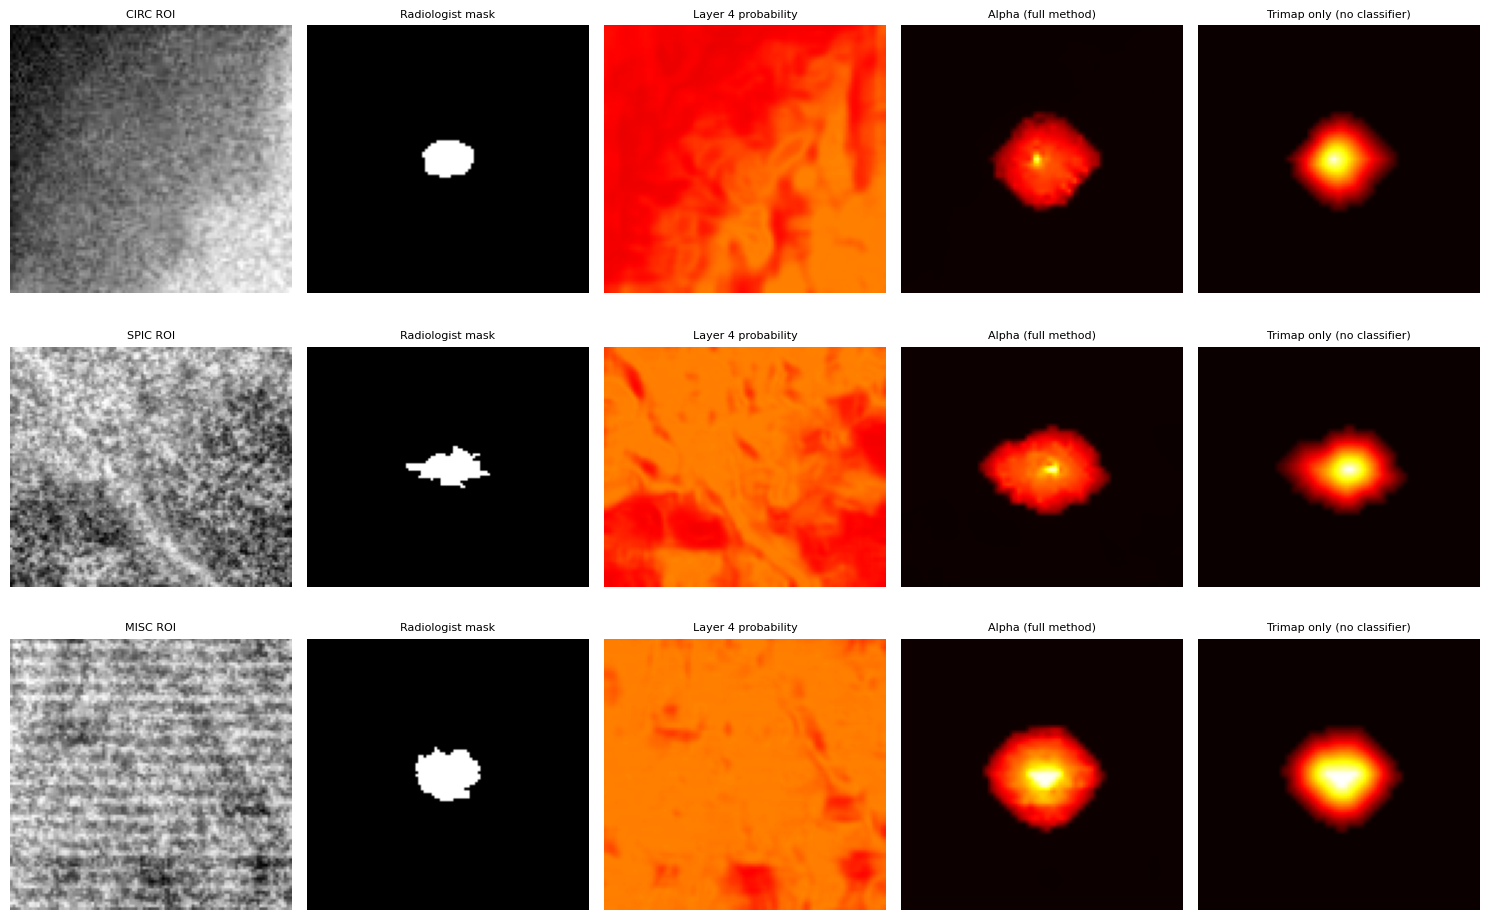

In [ ]:
# One test example per class: image, GT, Layer 4 probability, alpha, and the trimap-only baseline
pick = {}
for c in TARGET_CLASSES:
    for i in EVAL_TEST:
        if preprocessed_results[i]['class'] == c: pick[c] = i; break
fig, axes = plt.subplots(len(pick), 5, figsize=(15, 3.2 * len(pick)))
axes = np.atleast_2d(axes)
for r, (c, i) in enumerate(pick.items()):
    d = preprocessed_results[i]
    panels = [(d['roi'], 'gray', f"{c} ROI"), (d['gt_mask'], 'gray', "Radiologist mask"),
              (layer4_maps[i], 'hot', "Layer 4 probability"), (main_alphas[i], 'hot', "Alpha (full method)"),
              (base_alphas['trimap_distance (same grid)'][i], 'hot', "Trimap only (no classifier)")]
    for k, (im, cm, t) in enumerate(panels):
        axes[r, k].imshow(im, cmap=cm, vmin=None if cm == 'gray' else 0, vmax=None if cm == 'gray' else 1)
        axes[r, k].set_title(t, fontsize=8); axes[r, k].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "section12_alpha_samples.png"), dpi=140, bbox_inches='tight'); plt.show()

## Ablation - every arm trained on the train split

All arms use the same K, the same train/validation/test split, the same SVM grid tuned on validation, and are scored once on the full test split. `intensity_only` shows what the texture pipeline adds on top of local brightness.

In [ ]:
try:
    import torch
    DEV = 'cuda' if torch.cuda.is_available() else 'numpy'
except ImportError:
    torch, DEV = None, 'numpy'

class FastRBFProba:
    """P(mass) from a fitted RBF SVC through matrix products + sklearn's Platt parameters."""
    def __init__(self, svm, scaler, chunk=4096):
        self.mu, self.sd = scaler.mean_.astype(np.float64), scaler.scale_.astype(np.float64)
        self.sv = svm.support_vectors_.astype(np.float64); self.coef = svm.dual_coef_[0].astype(np.float64)
        self.b, self.gamma = float(svm.intercept_[0]), float(svm._gamma)
        self.A, self.B, self.chunk = float(svm.probA_[0]), float(svm.probB_[0]), chunk
        self.sv_sq = (self.sv ** 2).sum(1)
        self.sv32, self.sq32, self.c32 = self.sv.astype(np.float32), self.sv_sq.astype(np.float32), self.coef.astype(np.float32)
        if DEV != 'numpy':
            self.t_sv, self.t_c, self.t_sq = [torch.tensor(a, dtype=torch.float32, device=DEV) for a in (self.sv, self.coef, self.sv_sq)]
    def decision(self, X):
        out = np.empty(len(X), np.float64)
        for s in range(0, len(X), self.chunk):
            Z = ((X[s:s + self.chunk].astype(np.float64) - self.mu) / self.sd).astype(np.float32)
            if DEV == 'numpy':
                d2 = (Z ** 2).sum(1)[:, None] + self.sq32[None, :] - 2.0 * Z @ self.sv32.T
                np.maximum(d2, 0, out=d2); d2 *= -np.float32(self.gamma); np.exp(d2, out=d2)
                out[s:s + self.chunk] = (d2 @ self.c32).astype(np.float64) + self.b
            else:
                Zt = torch.tensor(Z, device=DEV)
                d2 = (Zt ** 2).sum(1, keepdim=True) + self.t_sq[None, :] - 2.0 * Zt @ self.t_sv.T
                out[s:s + self.chunk] = (torch.exp(-self.gamma * d2.clamp_min(0)) @ self.t_c).double().cpu().numpy() + self.b
        return out
    def proba(self, X):
        return (1.0 / (1.0 + np.exp(self.A * self.decision(X) - self.B))).astype(np.float32)

def center_patches(P, n_ch):
    P = P.reshape(len(P), n_ch, -1); return (P - P.mean(axis=2, keepdims=True)).reshape(len(P), -1)

def window_view(stack, ps):
    half = ps // 2
    return sliding_window_view(np.pad(stack, ((half, half), (half, half), (0, 0)), mode='reflect'), (ps, ps), axis=(0, 1))

def compute_histogram_map_fast(score_map, window_size=7):
    h, w, k = score_map.shape; area = float(window_size ** 2)
    s = np.empty_like(score_map, dtype=np.float32)
    for c in range(k):
        s[:, :, c] = cv2.boxFilter(score_map[:, :, c], -1, (window_size, window_size),
                                   borderType=cv2.BORDER_REFLECT, normalize=True) * area
    t = s.sum(axis=2, keepdims=True)
    return np.where(t > 1e-8, s / t, 1.0 / k).astype(np.float32)

def local_intensity_maps(roi):
    return [cv2.boxFilter(roi.astype(np.float32), -1, (w, w), borderType=cv2.BORDER_REFLECT) for w in INTENSITY_SCALES]

FIT_TOUCHED = set()      
WIN = PATCH_SINGLE
def has_l1(iid): return iid in layer1_maps[PATCH_SIZES[0]]

def channel_stats(channels, ids):
    FIT_TOUCHED.update(ids)
    n, s, s2 = 0, np.zeros(len(channels)), np.zeros(len(channels))
    for iid in ids:
        if not has_l1(iid): continue
        for c, (ps, kind) in enumerate(channels):
            m = layer1_maps[ps][iid][kind].astype(np.float64); s[c] += m.sum(); s2[c] += (m ** 2).sum()
        n += layer1_maps[PATCH_SIZES[0]][iid]['lipw'].size
    mean = s / n; return mean.astype(np.float32), np.sqrt(np.maximum(s2 / n - mean ** 2, 1e-12)).astype(np.float32)

def arm_stack(arm, iid):
    st = np.stack([layer1_maps[ps][iid][kind] for ps, kind in arm['channels']], axis=2).astype(np.float32)
    return (st - arm['mean'][None, None, :]) / arm['std'][None, None, :]

def arm_patches(arm, ids, max_per_img=200):
    FIT_TOUCHED.update(ids)
    out, rng = [], np.random.default_rng(SEED)
    for iid in sorted(ids):
        if not has_l1(iid) or preprocessed_results[iid]['trimap'] is None: continue
        st = arm_stack(arm, iid); tm = preprocessed_results[iid]['trimap']
        if st.shape[:2] != tm.shape: tm = cv2.resize(tm, (st.shape[1], st.shape[0]), interpolation=cv2.INTER_NEAREST)
        win = window_view(st, WIN)
        for val in (255, 0):
            pos = np.argwhere(tm == val)
            if len(pos) == 0: continue
            if len(pos) > max_per_img: pos = pos[rng.choice(len(pos), max_per_img, replace=False)]
            out.append(win[pos[:, 0], pos[:, 1]].reshape(len(pos), -1))
    return np.concatenate(out).astype(np.float32)

def set_templates(arm, tmpl):
    n_ch = len(arm['channels']); arm['tmpl'] = tmpl.astype(np.float32)
    Tc = center_patches(tmpl.reshape(len(tmpl), -1).astype(np.float32), n_ch)
    W = np.sign(Tc); W[W == 0] = 1.0; arm['W'], arm['Wn'] = W, np.linalg.norm(W, axis=1)
    arm['distinct'] = len({tuple(r) for r in W.astype(int)})

def make_arm(name, channels, templates='kmeans', K=None):
    arm = {'name': name, 'channels': channels, 'texture': channels is not None}
    if channels is None:
        arm['K'] = 0; return arm
    arm['mean'], arm['std'] = channel_stats(channels, train_ids)
    if isinstance(templates, str) and templates == 'kmeans':
        P = arm_patches(arm, train_ids)
        km = KMeans(n_clusters=K, init='k-means++', n_init=5, random_state=SEED).fit(center_patches(P, len(channels)))
        set_templates(arm, km.cluster_centers_.reshape(K, len(channels), WIN, WIN))
    else:                                                       # hand-designed shape detectors
        set_templates(arm, templates.reshape(K, len(channels), WIN, WIN))
    arm['K'] = K
    return arm

def arm_hist(arm, iid):
    st = arm_stack(arm, iid); h, w, C = st.shape
    pf = window_view(st, WIN).reshape(h * w, C * WIN * WIN).astype(np.float32)
    Pc = center_patches(pf, C)
    sc = ((Pc @ arm['W'].T) / (np.linalg.norm(Pc, axis=1, keepdims=True) * arm['Wn'][None, :] + 1e-8) + 1.0) * 0.5
    return compute_histogram_map_fast(sc.reshape(h, w, -1).astype(np.float32), HISTOGRAM_WINDOW)

def aligned(iid, hh, ww):
    tm, roi = preprocessed_results[iid]['trimap'], preprocessed_results[iid]['roi']
    if tm.shape != (hh, ww):  tm  = cv2.resize(tm,  (ww, hh), interpolation=cv2.INTER_NEAREST)
    if roi.shape != (hh, ww): roi = cv2.resize(roi, (ww, hh), interpolation=cv2.INTER_LINEAR)
    return tm, roi

def arm_tables(arm, ids):
    FIT_TOUCHED.update(ids)
    rng = np.random.default_rng(SEED); X, y = [], []
    for iid in sorted(ids):
        if preprocessed_results[iid]['trimap'] is None or not has_l1(iid): continue
        hh, ww = layer1_maps[PATCH_SIZES[0]][iid]['lipw'].shape
        tm, roi = aligned(iid, hh, ww)
        pm, pb = np.argwhere(tm == 255), np.argwhere(tm == 0)
        if len(pm) == 0 or len(pb) == 0: continue
        n = min(len(pm), len(pb), MAX_PER_CLASS_PER_IMG); sel = []
        for pos, lab in ((pm, 1), (pb, 0)):
            if len(pos) > n: pos = pos[rng.choice(len(pos), n, replace=False)]
            sel.append((pos, lab))
        pos_all = np.concatenate([p for p, _ in sel]); lab_all = np.concatenate([np.full(len(p), l) for p, l in sel])
        feats = [np.stack([im[pos_all[:, 0], pos_all[:, 1]] for im in local_intensity_maps(roi)], axis=1)]
        if arm['texture']: feats.insert(0, arm_hist(arm, iid)[pos_all[:, 0], pos_all[:, 1]])
        X.append(np.concatenate(feats, axis=1)); y.append(lab_all)
    return np.concatenate(X).astype(np.float32), np.concatenate(y)

def train_arm(arm):
    Xtr, ytr = arm_tables(arm, train_ids); Xva, yva = arm_tables(arm, val_ids)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xva_s = sc.transform(Xtr), sc.transform(Xva)
    rng = np.random.default_rng(SEED)
    gi = rng.choice(len(Xtr_s), min(MAX_TUNE_FIT, len(Xtr_s)), replace=False)
    best = (-1, None, None)
    for C in SVM_C_VALUES:
        for g in SVM_GAMMA_VALUES:
            m = SVC(kernel='rbf', C=C, gamma=g, class_weight='balanced', random_state=SEED).fit(Xtr_s[gi], ytr[gi])
            s = balanced_accuracy_score(yva, m.predict(Xva_s))
            if s > best[0] + 1e-12: best = (s, C, g)
    fi = rng.choice(len(Xtr_s), min(MAX_FIT, len(Xtr_s)), replace=False)
    svm = SVC(kernel='rbf', C=best[1], gamma=best[2], class_weight='balanced', probability=True, random_state=SEED).fit(Xtr_s[fi], ytr[fi])
    fast = FastRBFProba(svm, sc)
    xs = Xva[::max(1, len(Xva) // 3000)][:3000]
    err = float(np.abs(fast.proba(xs) - svm.predict_proba(sc.transform(xs))[:, 1]).max())
    arm.update(svm=svm, scaler=sc, fast=fast, use_fast=err <= 0.01, val_bal_acc=float(best[0]),
               params={'C': best[1], 'gamma': str(best[2])}, fast_err=err, train_rows=len(ytr), val_rows=len(yva))
    return arm

def arm_prob_map(arm, iid):
    hh, ww = layer1_maps[PATCH_SIZES[0]][iid]['lipw'].shape
    _, roi = aligned(iid, hh, ww)
    ims = [im.reshape(-1) for im in local_intensity_maps(roi)]
    X = np.stack(ims, axis=1)
    if arm['texture']:
        hm = arm_hist(arm, iid); X = np.concatenate([hm.reshape(-1, hm.shape[2]), X], axis=1)
    p = arm['fast'].proba(X) if arm['use_fast'] else np.concatenate(
        [arm['svm'].predict_proba(arm['scaler'].transform(X[s:s + 20000]))[:, 1] for s in range(0, len(X), 20000)])
    return p.reshape(hh, ww).astype(np.float32)

def make_manual_templates_k(k, ps=WIN):
    c = ps // 2
    def blank(): return np.full((ps, ps), 0.2, np.float32)
    base = []
    t = blank(); t[:, c] = 0.9; base.append(t)
    t = blank(); t[c, :] = 0.9; base.append(t)
    t = blank(); np.fill_diagonal(t, 0.9); base.append(t)
    t = blank(); np.fill_diagonal(np.fliplr(t), 0.9); base.append(t)
    t = blank(); t[c, :] = 0.9; t[:, c] = 0.9; base.append(t)
    t = blank(); t[0, :] = 0.9; t[:, 0] = 0.9; base.append(t)
    t = np.full((ps, ps), 0.9, np.float32); t[c, c] = 0.2; base.append(t)
    t = blank(); t[c-1:c+2, c-1:c+2] = 0.9; base.append(t)
    out, i = list(base), 0
    while len(out) < k:
        out.append(np.rot90(base[i % len(base)], 1 + (i // len(base)))); i += 1
    return np.stack(out[:k]).astype(np.float32)

print(f"Arm infrastructure ready (fast predictor on: {DEV}).")

Arm infrastructure ready (fast predictor on: cuda).


In [ ]:
t0 = time.time()
arms = {
    'manual_3x3'    : make_arm('manual_3x3',    [(3, 'lipw')], templates=make_manual_templates_k(FINAL_K), K=FINAL_K),
    'single_5x5'    : make_arm('single_5x5',    [(5, 'lipw')], templates='kmeans', K=FINAL_K),
    'intensity_only': make_arm('intensity_only', None),
}
for name, arm in arms.items():
    train_arm(arm)
    extra = f", {arm['distinct']}/{arm['K']} distinct sign patterns" if arm['texture'] else ""
    print(f"{name:<15} val balanced acc {arm['val_bal_acc']:.4f}  params {arm['params']}  "
          f"fast-vs-sklearn max diff {arm['fast_err']:.4f}{extra}  [{(time.time()-t0)/60:.1f} min]")

arm_alphas = {}
for name, arm in arms.items():
    arm_alphas[name] = {i: solve_alpha(arm_prob_map(arm, i), preprocessed_results[i]['trimap_eval'],
                                       preprocessed_results[i]['roi'], VARIANTS[L5_MAIN])
                        for i in tqdm(EVAL_TEST, desc=name)}
arm_alphas['six_channel_no_hybrid'] = {i: solve_alpha(layer4_maps[i], preprocessed_results[i]['trimap_eval'],
                                                      preprocessed_results[i]['roi'], VARIANTS[L5_PLAIN]) for i in tqdm(EVAL_TEST, desc='no_hybrid')}
arm_alphas['full_method'] = main_alphas

ORDER = ['manual_3x3', 'single_5x5', 'six_channel_no_hybrid', 'full_method', 'intensity_only']
arm_df = {k: eval_many(arm_alphas[k]) for k in ORDER}
val_acc_of = {'manual_3x3': arms['manual_3x3']['val_bal_acc'], 'single_5x5': arms['single_5x5']['val_bal_acc'],
              'six_channel_no_hybrid': svm_results['val_balanced_acc'], 'full_method': svm_results['val_balanced_acc'],
              'intensity_only': arms['intensity_only']['val_bal_acc']}
rows = []
for k in ORDER:
    d = arm_df[k]; row = {'arm': k, 'n': len(d), 'dice': d['dice'].mean(), 'sensitivity': d['sensitivity'].mean(),
                          'specificity': d['specificity'].mean(), 'hd95': d['hd95'].mean(), 'alpha_mae': d['alpha_mae'].mean(),
                          'classifier_val_bal_acc': val_acc_of[k]}
    for c in TARGET_CLASSES: row[f'dice_{c}'] = d[d['class'] == c]['dice'].mean()
    rows.append(row)
ablation_table = pd.DataFrame(rows)
ablation_table.to_csv(os.path.join(RESULTS_DIR, "ablation_table.csv"), index=False)
print("\nABLATION (full test split, every arm re-trained on train, tuned on validation)")
print(ablation_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

manual_3x3      val balanced acc 0.5502  params {'C': 0.1, 'gamma': 'scale'}  fast-vs-sklearn max diff 0.0050, 8/8 distinct sign patterns  [4.8 min]
single_5x5      val balanced acc 0.5473  params {'C': 0.1, 'gamma': 'scale'}  fast-vs-sklearn max diff 0.0050, 8/8 distinct sign patterns  [9.6 min]
intensity_only  val balanced acc 0.5475  params {'C': 0.1, 'gamma': 'scale'}  fast-vs-sklearn max diff 0.0049  [13.3 min]


no_hybrid: 100%|██████████| 269/269 [00:15<00:00, 17.83it/s]



ABLATION (full test split, every arm re-trained on train, tuned on validation)
                  arm   n   dice  sensitivity  specificity   hd95  alpha_mae  classifier_val_bal_acc  dice_CIRC  dice_SPIC  dice_MISC
           manual_3x3 269 0.7428       0.7749       0.9905 5.2404     0.0453                  0.5502     0.7291     0.7883     0.7125
           single_5x5 269 0.7435       0.7696       0.9908 5.1707     0.0452                  0.5473     0.7257     0.7902     0.7160
six_channel_no_hybrid 269 0.7508       0.7569       0.9920 5.1391     0.0449                  0.5446     0.7374     0.7911     0.7253
          full_method 269 0.7456       0.7734       0.9907 5.1606     0.0452                  0.5446     0.7294     0.7888     0.7201
       intensity_only 269 0.7417       0.7648       0.9908 5.1472     0.0451                  0.5475     0.7255     0.7856     0.7154


## Paired comparisons (patient-level bootstrap, 95% CI)

In [ ]:
pairs = [('full_method', main_alphas, 'trimap_distance (same grid)', base_df['trimap_distance (same grid)']),
         ('full_method', main_alphas, 'trimap_distance (full res)', base_df['trimap_distance (full res)']),
         ('full_method', main_alphas, 'intensity_only', arm_df['intensity_only']),
         ('full_method', main_alphas, 'single_5x5', arm_df['single_5x5']),
         ('full_method', main_alphas, 'manual_3x3', arm_df['manual_3x3']),
         ('full_method', main_alphas, 'six_channel_no_hybrid', arm_df['six_channel_no_hybrid'])]
rows = []
for a, _, b, dfb in pairs:
    dfa = arm_df[a]
    for metric in ('dice', 'hd95'):
        m, lo, hi, n = paired_bootstrap(dfa, dfb, metric)
        rows.append({'A': a, 'B': b, 'metric': metric, 'mean_diff_A_minus_B': m, 'ci_low': lo, 'ci_high': hi, 'n': n,
                     'significant': (lo > 0) or (hi < 0)})
cmp_df = pd.DataFrame(rows); cmp_df.to_csv(os.path.join(RESULTS_DIR, "comparisons_ci.csv"), index=False)
print(cmp_df.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("\nFor Dice, positive = the full method is better. For HD95 (pixels), negative = the full method is better.")


          A                           B metric  mean_diff_A_minus_B  ci_low  ci_high   n  significant
full_method trimap_distance (same grid)   dice              -0.0552 -0.0706  -0.0411 269         True
full_method trimap_distance (same grid)   hd95              +1.0930 +0.8561  +1.3187 269         True
full_method  trimap_distance (full res)   dice              -0.0606 -0.0764  -0.0460 269         True
full_method  trimap_distance (full res)   hd95              +2.0020 +1.7484  +2.2578 269         True
full_method              intensity_only   dice              +0.0039 +0.0019  +0.0060 269         True
full_method              intensity_only   hd95              +0.0133 -0.0586  +0.0991 269        False
full_method                  single_5x5   dice              +0.0022 -0.0003  +0.0044 269        False
full_method                  single_5x5   hd95              -0.0102 -0.0550  +0.0339 269        False
full_method                  manual_3x3   dice              +0.0028 +0.0000  +0.00

## Consolidation

In [ ]:
final_results = {
    'project': 'GrC-Based Image Matting on CBIS-DDSM', 'base_paper': 'Hu, Pang, Shi (2016), Knowledge-Based Systems 102, 51-63',
    'dataset': {'images': int(len(final_df_loaded)), 'lesions': int(final_df_loaded['lesion_key'].nunique()),
                'patients': int(final_df_loaded['patient_id'].nunique()),
                'split_images': {'train': len(train_ids), 'val': len(val_ids), 'test': len(test_ids)},
                'classes': {c: int((final_df_loaded['class'] == c).sum()) for c in TARGET_CLASSES}},
    'config': {'seed': SEED, 'patch_sizes': PATCH_SIZES, 'channels': [list(c) for c in CHANNELS6], 'K': int(FINAL_K),
               'layer5_variant': L5_MAIN, 'seed_rule': 'erode up to 6 px (never the whole mask), dilate 10 px', 'hybrid_gamma': HYBRID_GAMMA, 'max_nodes': MAX_NODES, 'lambda': LAMBDA_PROPAGATION},
    'svm': svm_results, 'layer5_selection_val': sel.to_dict(orient='records'),
    'per_class_test': per_class.to_dict(orient='records'), 'baselines_test': base_table.to_dict(orient='records'),
    'ablation_test': ablation_table.to_dict(orient='records'), 'comparisons': cmp_df.to_dict(orient='records'),
    'n_test_images_evaluated': int(len(eval_df)), 'test_used_for_fitting_or_selection': False}
json.dump(final_results, open(os.path.join(RESULTS_DIR, "final_results.json"), 'w'), indent=2, default=float)

lines = ["GrC IMAGE MATTING ON CBIS-DDSM - RESULTS SUMMARY (v2)", "=" * 60, "",
         f"Split (images)   : train {len(train_ids)} / val {len(val_ids)} / test {len(test_ids)}  (patient-grouped)",
         f"Test evaluated   : {len(eval_df)} images",
         f"K / Layer 5      : K={FINAL_K} / {L5_MAIN}",
         f"SVM (validation) : balanced accuracy {svm_results['val_balanced_acc']:.4f} (texture adds "
         f"{svm_results['val_balanced_acc'] - svm_results['intensity_only_val_balanced_acc']:+.4f} over intensity only)", "",
         "Per-class results, TEST split", "-" * 60, per_class.to_string(index=False, float_format=lambda x: f"{x:.4f}"), "",
         "Classifier-free baselines, TEST split", "-" * 60, base_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"), "",
         "Ablation, TEST split (every arm re-trained)", "-" * 60, ablation_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"), "",
         "Paired comparisons (patient bootstrap)", "-" * 60, cmp_df.to_string(index=False, float_format=lambda x: f"{x:+.4f}"), "",
         "Scope notes", "-" * 60,
         "1. No NORM class: the curated CBIS-DDSM release has abnormality cases only.",
         "2. GT is the radiologist annotation (not pixel-exact truth); evaluation seeds are derived from it (oracle seeds): mask eroded up to 6 px (a small core is kept for tiny lesions, never the whole mask), background outside the mask dilated 10 px.",
         "3. Layer 5 is solved on a bounded grid (max_nodes); 'same grid' baseline rows use identical resolution.",
         "4. Test images were never used for fitting or selection."]
summary = "\n".join(lines); open(os.path.join(RESULTS_DIR, "results_summary.txt"), 'w').write(summary); print(summary)

GrC IMAGE MATTING ON CBIS-DDSM - RESULTS SUMMARY (v2)

Split (images)   : train 642 / val 156 / test 269  (patient-grouped)
Test evaluated   : 269 images
K / Layer 5      : K=8 / paper_hybrid_mu1
SVM (validation) : balanced accuracy 0.5446 (texture adds +0.0011 over intensity only)

Per-class results, TEST split
------------------------------------------------------------
class  n   dice  dice_std  sensitivity  specificity   hd95  alpha_mae
 CIRC 89 0.7294    0.1619       0.7684       0.9918 4.5509     0.0436
 SPIC 88 0.7888    0.1534       0.7963       0.9897 5.5375     0.0476
 MISC 92 0.7201    0.1594       0.7563       0.9907 5.3899     0.0445

Classifier-free baselines, TEST split
------------------------------------------------------------
                       method   n   dice  sensitivity  specificity    hd95  alpha_mae
                  trimap_zero 269 0.3284       0.2252       1.0000  8.6949     0.0287
                   trimap_one 269 0.4527       1.0000       0.9132 10.432

In [ ]:
def verify_notebook4():
    fit_ids = train_ids | val_ids
    checks = {
        "evaluation images are all test images"        : set(eval_df['image_id']) <= test_ids,
        "no test image in train/val"                   : not (test_ids & fit_ids),
        "layer 5 variant chosen on validation images"  : set(EVAL_VAL) <= val_ids,
        "no test image reached any fitting routine"    : bool(FIT_TOUCHED) and not (FIT_TOUCHED & test_ids) and FIT_TOUCHED <= (train_ids | val_ids),
        "same test images for every method"            : all(set(arm_df[k]['image_id']) == set(eval_df['image_id']) for k in ORDER)
                                                         and all(set(d['image_id']) == set(eval_df['image_id']) for d in base_df.values()),
        "baselines present"                            : len(base_table) >= 4,
        "evaluation seeds never use the whole mask"    : all(((preprocessed_results[i]['trimap_eval'] == 255) <= (preprocessed_results[i]['gt_mask'] > 127)).all() for i in EVAL_TEST)
                                                         and np.mean([(preprocessed_results[i]['trimap_eval'] == 255).sum() < (preprocessed_results[i]['gt_mask'] > 127).sum() for i in EVAL_TEST]) >= 0.95,
        "alpha in [0,1]"                               : all(a.min() >= 0 and a.max() <= 1 for a in main_alphas.values()),
        "metrics finite for >= 99% of images"          : eval_df['dice'].notna().mean() >= 0.99,
        "full_method row equals main result"           : abs(ablation_table.set_index('arm').loc['full_method', 'dice'] - eval_df['dice'].mean()) < 1e-9,
        "outputs saved"                                : all(os.path.exists(os.path.join(d, f)) for d, f in [
            (ALPHAS_DIR, "alpha_maps_full.npz"), (RESULTS_DIR, "evaluation_per_image.csv"), (RESULTS_DIR, "ablation_table.csv"),
            (RESULTS_DIR, "baselines_table.csv"), (RESULTS_DIR, "comparisons_ci.csv"), (RESULTS_DIR, "final_results.json")]),
    }
    print("=" * 60); print("NOTEBOOK 4 VERIFICATION"); print("=" * 60)
    ok = True
    for k, v in checks.items():
        print(f"  {'OK  ' if v else 'FAIL'}  {k}"); ok = ok and v
    print("=" * 60); print("CBIS-DDSM phase complete." if ok else "Review failures.")
    return ok

verify_notebook4()

NOTEBOOK 4 VERIFICATION
  OK    evaluation images are all test images
  OK    no test image in train/val
  OK    layer 5 variant chosen on validation images
  OK    no test image reached any fitting routine
  OK    same test images for every method
  OK    baselines present
  OK    evaluation seeds never use the whole mask
  OK    alpha in [0,1]
  OK    metrics finite for >= 99% of images
  OK    full_method row equals main result
  OK    outputs saved
CBIS-DDSM phase complete.


True